In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [30]:
df = pd.read_csv(r'Unemployment in India.csv')

print("Database Shape:",df.shape)
print("\nColumn Names:",df.columns)
print("\nDataset Info:")
df.info()


Database Shape: (768, 7)

Column Names: Index(['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)',
       ' Estimated Employed', ' Estimated Labour Participation Rate (%)',
       'Area'],
      dtype='object')

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float6

In [31]:
df.columns = df.columns.str.strip() 
df = df.dropna()
df['Date'] = pd.to_datetime(df['Date'].str.strip())
df['Month'] = df['Date'].dt.month_name()
print(list(df.columns))

['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area', 'Month']


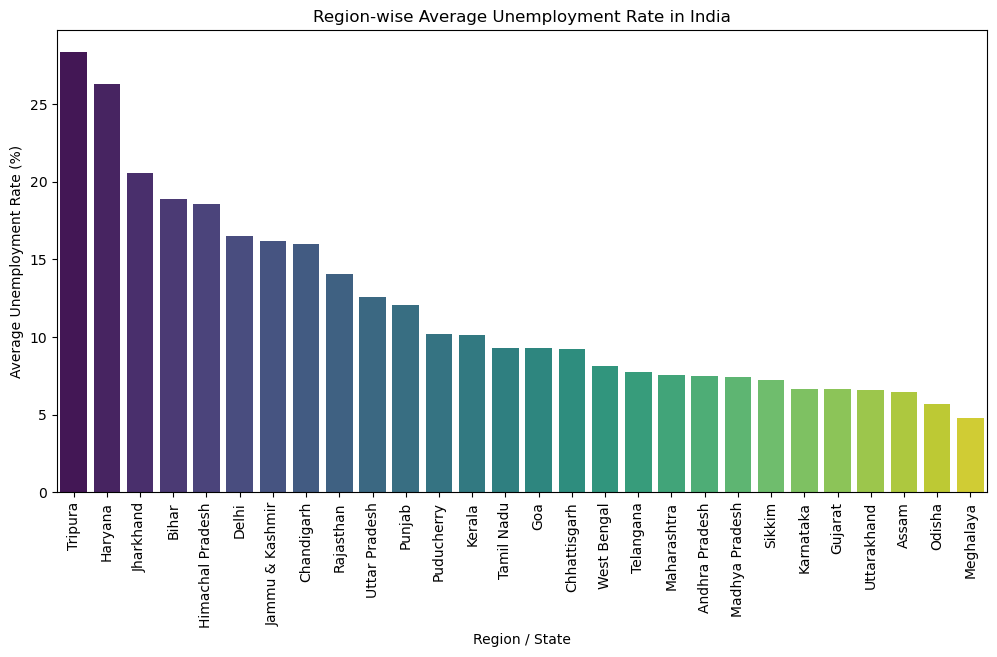

In [32]:

plt.figure(figsize=(12,6))
df.columns = df.columns.str.strip()
rate_col = [col for col in df.columns if 'Unemployment Rate' in col][0]
region_col = [col for col in df.columns if 'Region' in col or 'State' in col][0]

region_umemp = df.groupby(region_col)[rate_col].mean().sort_values(ascending=False)

sns.barplot(x=region_umemp.index, y=region_umemp.values, palette='viridis')
plt.xticks(rotation=90)
plt.title('Region-wise Average Unemployment Rate in India')
plt.xlabel('Region / State')
plt.ylabel('Average Unemployment Rate (%)')
plt.show()

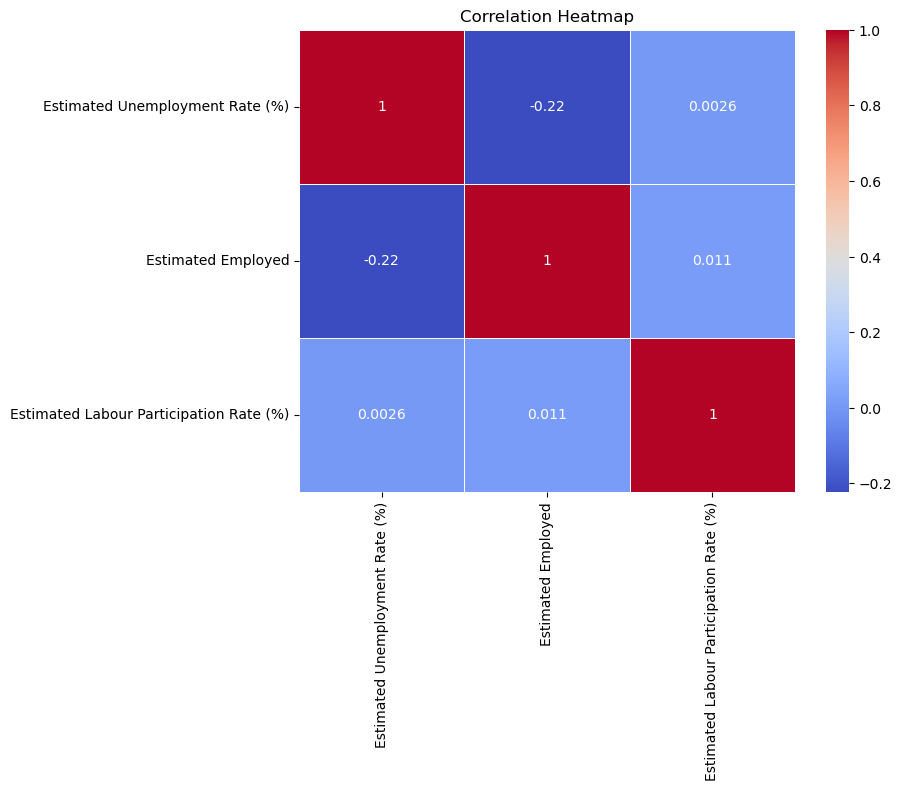

In [33]:
plt.figure(figsize=(8,6))
numeric_df = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(),annot=True, cmap='coolwarm',linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()